# Analysis - Perceptual load / working memory manipulation

Final GLM analysis on alignment-adjusted data.

## Used montage

![montage](img/montage.png)

# Set parameters and read data

In [1]:
import os

import matplotlib.pyplot as plt
import mne
import mne_bids
import mne_nirs
import numpy as np
import pandas as pd
import glob

import seaborn as sns
import statsmodels.formula.api as smf
import matplotlib as mpl

from itertools import compress
from nilearn.plotting import plot_design_matrix
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.multitest import multipletests

# BIDS dataset and task
task = "lettersearch"
bids_root = "data/lettersearch_BIDS"
datatype = 'nirs'
bids_folder = mne_bids.BIDSPath(root=bids_root, datatype=datatype)
nirs_files = bids_folder.match()

# Prepare folder for processed data
glm_folder = "data/glm_data"
if not os.path.isdir(glm_folder):
    os.mkdir(glm_folder)

# Parameters used
sci_limit = 0.8
excluded_participants = []

# For visualization
subjects_dir = str(mne.datasets.sample.data_path()) + '/subjects'
mne.datasets.fetch_fsaverage(subjects_dir=subjects_dir)
mne.set_config('MNE_NIRS_FOLD_PATH', 'data/fOLD-public/Supplementary')

# Offsets
offsets_path = "data/trigger_offsets.csv"
if os.path.exists(offsets_path):
    trigger_offsets = pd.read_csv(offsets_path).set_index('subject')['lag_sec']
    print(f"Loaded trigger offsets for {len(trigger_offsets)} subjects:")
    print(trigger_offsets.to_string())
else:
    trigger_offsets = pd.Series(dtype=float)
    print(f"WARNING: {offsets_path} not found — no ACC offsets applied")

0 files missing from root.txt in /Users/alexander.kvist/mne_data/MNE-sample-data/subjects
0 files missing from bem.txt in /Users/alexander.kvist/mne_data/MNE-sample-data/subjects/fsaverage
Loaded trigger offsets for 16 subjects:
subject
P1      0.0
P10    13.0
P11     5.0
P12     0.0
P13     0.0
P14     2.0
P15     3.0
P17     0.0
P2      0.0
P3      0.0
P4      0.0
P5      8.0
P6     -7.0
P7     45.0
P8      0.0
P9     -5.0


# Set up design matrix

The design matrix includes practice and experimental condtions, a constant + cosine drift regressors, short channel regressors, a nuisance regressor for the pause in the protocol, and finally [TCCA](https://doi.org/10.1016/j.neuroimage.2019.116472) regressors built from accelerometer and gyroscope data in auxilliary channels.

Drift regressor cutoff is based on the ISI in the experiment, according to MNE-NIRS and Nilearn documentation:

> the cutoff period (1/high_pass) should be set as the longest period between two trials of the same condition multiplied by 2.

- <https://mne.tools/mne-nirs/stable/auto_examples/general/plot_14_glm_components.html#drift-regressors>
- <https://nilearn.github.io/dev/auto_examples/04_glm_first_level/plot_first_level_details.html> 

In this case, the longest ISI was determined to be 16.9 seconds. This can be computed via the function [_longest_inter_annotation_interval_](https://mne.tools/mne-nirs/stable/generated/mne_nirs.experimental_design.longest_inter_annotation_interval.html). This means that the high_pass value should be 1 / (2*16.9) = 1 / 33.8 ≈ 0.0295

Loading /Users/alexander.kvist/project_local/Perceptual-fnirs/data/lettersearch_BIDS/sub-P1/nirs/sub-P1_task-lettersearch_nirs.snirf
Found jitter of 0.000000% in sample times.
Reading events from data/lettersearch_BIDS/sub-P1/nirs/sub-P1_task-lettersearch_events.tsv.
Reading channel info from data/lettersearch_BIDS/sub-P1/nirs/sub-P1_task-lettersearch_channels.tsv.
Not fully anonymizing info - keeping hand, his_id, sex of subject_info
Reading 0 ... 5014  =      0.000 ...   985.793 secs...
Reading 0 ... 5014  =      0.000 ...   985.793 secs...
          ACCEL_X_1  ACCEL_X_2  ACCEL_Y_2  ACCEL_Z_2  GYRO_X_2  GYRO_Y_2  \
times                                                                      
0.000000  -0.025000  -0.004000   1.060000  -9.197000 -0.015251  0.000000   
0.196608  -0.058828  -0.078241   1.150174  -9.190414  0.052679 -0.045756   
0.393216   0.028000  -0.210378   1.011860  -9.194551 -0.007595 -0.008514   
0.589824  -0.028556  -0.117207   1.053747  -9.219788 -0.047704 -0.00099

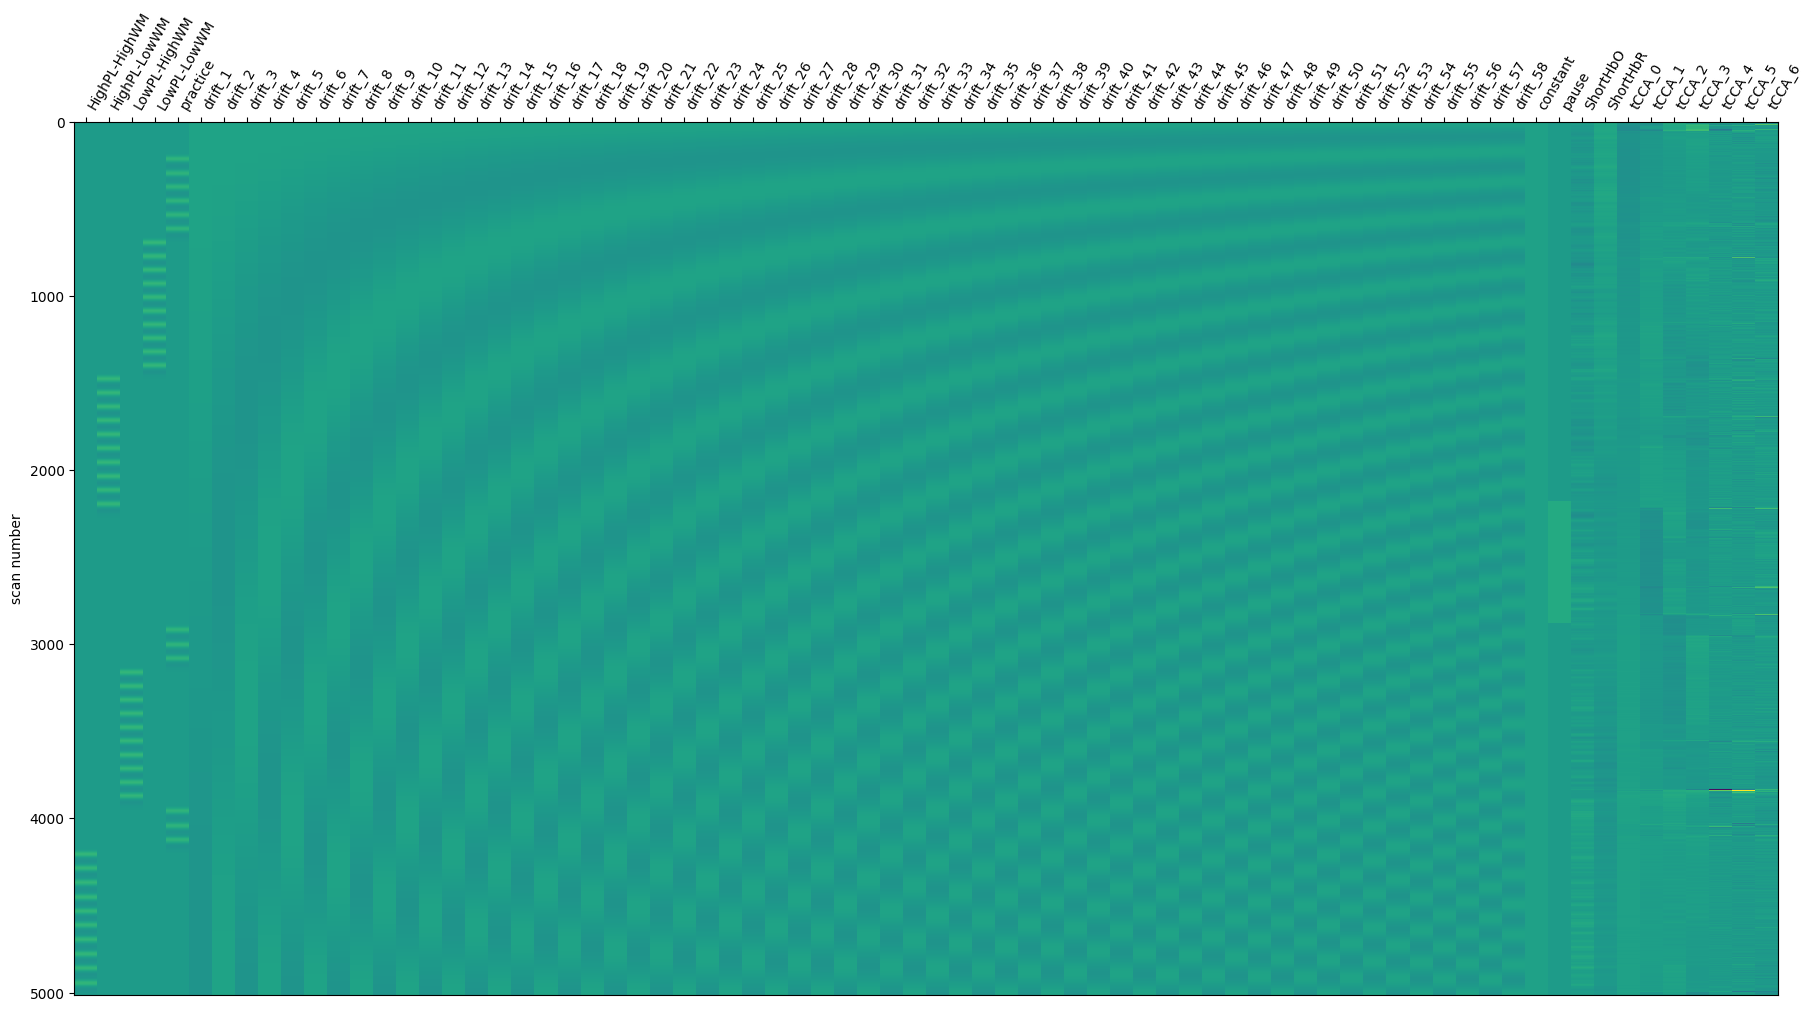

In [2]:
# Get all subjects in a sorted list
all_subjects = [file.subject for file in nirs_files]
all_subjects = sorted(list(set(all_subjects)))

# Get hemo data for one subject to illustrate design matrix
subject = all_subjects[0]
bids_path = mne_bids.BIDSPath(subject=subject, task=task,
                            suffix=datatype, datatype=datatype,
                            root=bids_root)

raw_intensity = mne_bids.read_raw_bids(bids_path=bids_path)

# Split into long/short
long_chs = mne_nirs.channels.get_long_channels(raw_intensity)
short_chs = mne_nirs.channels.get_short_channels(raw_intensity)

# Convert to hemoglobin
raw_od_long = mne.preprocessing.nirs.optical_density(long_chs)
raw_od_short = mne.preprocessing.nirs.optical_density(short_chs)
raw_haemo_long = mne.preprocessing.nirs.beer_lambert_law(raw_od_long, ppf=0.1)
raw_haemo_short = mne.preprocessing.nirs.beer_lambert_law(raw_od_short, ppf=0.1)

# Create a design matrix
design_matrix = mne_nirs.experimental_design.make_first_level_design_matrix(raw_haemo_long,
                                                                            drift_model="cosine",
                                                                            stim_dur=5,
                                                                            hrf_model="glover",
                                                                            high_pass=0.0295)

# Add a boxcar regressor for the long pause
# First get gaps between blocks
onsets = raw_haemo_long.annotations.onset
durations = raw_haemo_long.annotations.duration
ends = onsets + durations
gaps = onsets[1:] - ends[:-1]

# The longest gap is guaranteed to be the pause
pause_idx = np.argmax(gaps)
pause_start_sec = ends[pause_idx]
pause_stop_sec = onsets[pause_idx+1]

# Create a pause regressor (can be confirmed visually)
pause_regressor = np.zeros(len(raw_haemo_long.times))
start_idx = np.searchsorted(raw_haemo_long.times, pause_start_sec)
stop_idx = np.searchsorted(raw_haemo_long.times, pause_stop_sec)
pause_regressor[start_idx:stop_idx] = 1.0
design_matrix["pause"] = pause_regressor

# Add short separation regressors
design_matrix["ShortHbO"] = np.mean(
    raw_haemo_short.copy().pick(picks="hbo").get_data(), axis=0
)
design_matrix["ShortHbR"] = np.mean(
    raw_haemo_short.copy().pick(picks="hbr").get_data(), axis=0
)

# Add acceleration regressors
aux_df = mne_nirs.io.snirf.read_snirf_aux_data(raw_intensity.filenames[0], raw_intensity)
print(aux_df.head())

aux_all = aux_df.to_numpy()
nirs_data = raw_haemo_long.copy().pick(picks="hbo").get_data().T

reg, tcca_info = mne_nirs.experimental_design.rtcca(
    nirs_data,
    aux_all,
    tau=1,
    n_emb=3,
    ct=0.3,
    pca_fnirs = False,
    pca_aux = False,
    shrink=True
)

print(reg.shape)
reg_names = [f"tCCA_{i}" for i in range(reg.shape[1])]
for i, name in zip(range(reg.shape[1]), reg_names):
    design_matrix[name] = reg[:, i]

# Plot final matrix
fig = plot_design_matrix(design_matrix)
plt.show()

In [ ]:
# Go through data for each subject
cha_frames = []
for subject in all_subjects:
    
    # Get SNIRF file for this subject
    bids_path = mne_bids.BIDSPath(subject=subject, task=task,
                            suffix=datatype, datatype=datatype,
                            root=bids_root)
    
    print(f"Processing {bids_path}..")
    if not os.path.exists(bids_path):
        print(f"No SNIRF file, skip: {bids_path}")
        continue

    # Raw data
    raw_intensity = mne_bids.read_raw_bids(bids_path=bids_path)

    # Apply per-subject trigger offset from alignment_notebook
    if subject in trigger_offsets.index:
        _off = float(trigger_offsets[subject])
        _ann = raw_intensity.annotations
        raw_intensity.set_annotations(mne.Annotations(
            onset       = _ann.onset + _off,
            duration    = _ann.duration,
            description = _ann.description,
        ))
        print(f"  trigger offset applied: {_off:+.3f} s")
    else:
        print(f"  no offset for {subject} — using as-is")

    # Split into long/short
    long_chs = mne_nirs.channels.get_long_channels(raw_intensity)
    short_chs = mne_nirs.channels.get_short_channels(raw_intensity)

    # Convert to OD
    raw_od_long = mne.preprocessing.nirs.optical_density(long_chs)
    raw_od_short = mne.preprocessing.nirs.optical_density(short_chs)

    # Channel quality
    sci = mne.preprocessing.nirs.scalp_coupling_index(raw_od_long)
    bad_channels = list(compress(raw_od_long.ch_names, sci < sci_limit))
    
    # Get bad channel names as e.g. S1_D1 instead of S1_D1 760 and S1_D1 850
    bad_channels = np.unique([channel.replace(" 760", "").replace(" 850", "") for channel in np.unique(bad_channels)]).tolist()
    print(f"Bad channels with SCI < {sci_limit}:")
    print(bad_channels)

    # Use the MBLL to convert into hemoglobin changes
    raw_haemo_long = mne.preprocessing.nirs.beer_lambert_law(raw_od_long, ppf=0.1)
    raw_haemo_short = mne.preprocessing.nirs.beer_lambert_law(raw_od_short, ppf=0.1)

    # Where to store results from the GLM analysis
    glm_fname = f"{glm_folder}/{subject}_glm.h5"

    # Create a design matrix
    design_matrix = mne_nirs.experimental_design.make_first_level_design_matrix(raw_haemo_long,
                                                                                stim_dur=5,
                                                                                drift_model="cosine",
                                                                                hrf_model="glover",
                                                                                high_pass=0.0295)
    design_matrix["ShortHbO"] = np.mean(
        raw_haemo_short.copy().pick(picks="hbo").get_data(), axis=0
    )
    design_matrix["ShortHbR"] = np.mean(
        raw_haemo_short.copy().pick(picks="hbr").get_data(), axis=0
    )

    # Add a boxcar regressor for the long pause
    # First get gaps between blocks
    onsets = raw_haemo_long.annotations.onset
    durations = raw_haemo_long.annotations.duration
    ends = onsets + durations
    gaps = onsets[1:] - ends[:-1]
    
    # The longest gap is guaranteed to be the pause
    pause_idx = np.argmax(gaps)
    pause_start_sec = ends[pause_idx]
    pause_stop_sec = onsets[pause_idx+1]
    
    # Create a pause regressor (can be confirmed visually)
    pause_regressor = np.zeros(len(raw_haemo_long.times))
    start_idx = np.searchsorted(raw_haemo_long.times, pause_start_sec)
    stop_idx = np.searchsorted(raw_haemo_long.times, pause_stop_sec)
    pause_regressor[start_idx:stop_idx] = 1.0
    design_matrix["pause"] = pause_regressor

    # Add acceleration regressors via TCCA
    aux_df = mne_nirs.io.snirf.read_snirf_aux_data(raw_intensity.filenames[0], raw_intensity)
    aux_all = aux_df.to_numpy()
    nirs_data = raw_haemo_long.copy().pick(picks="hbo").get_data().T
    reg, tcca_info = mne_nirs.experimental_design.rtcca(
        nirs_data,
        aux_all,
        tau=1,
        n_emb=3,
        ct=0.3,
        pca_fnirs = False,
        pca_aux = True,
        shrink=True
    )
    reg_names = [f"tCCA_{i}" for i in range(reg.shape[1])]
    for i, name in zip(range(reg.shape[1]), reg_names):
        design_matrix[name] = reg[:, i]

    # Save per-subject VIF
    vif_vals = {design_matrix.columns[i]: variance_inflation_factor(design_matrix.values, i)
                for i in range(design_matrix.shape[1])}
    pd.Series(vif_vals).to_csv(f"{glm_folder}/{subject}_vif.csv")

    # Run GLM and save
    glm_est = mne_nirs.statistics.run_glm(raw_haemo_long, design_matrix, noise_model="auto")
    glm_est.save(glm_fname, overwrite=True)

    # If we want to visualize subject-level GLM
    #glm_est.plot_topo(conditions=['HighPL-HighWM', 'HighPL-LowWM', 'LowPL-HighWM', 'LowPL-LowWM'])
    #plt.show()

    # Append results per channel to larger dataframe for later export
    cha = glm_est.to_dataframe()

    # Add 'channel_ok' column as True for good channels, False for bad channels
    cha['channel_ok'] = cha['ch_name'].apply(lambda x: x.split(' ')[0] not in bad_channels)

    # Append to final dataframes
    cha['subject'] = subject
    cha_frames.append(cha)

cha_data = pd.concat(cha_frames, ignore_index=True)
cha_data.to_csv("data/cha_data.csv")

print('done')

# Also save a raw object for later plotting purposes
raw_haemo_long.save("data/raw.fif", overwrite=True)

Processing data/lettersearch_BIDS/sub-P1/nirs/sub-P1_task-lettersearch_nirs.snirf..
Loading /Users/alexander.kvist/project_local/Perceptual-fnirs/data/lettersearch_BIDS/sub-P1/nirs/sub-P1_task-lettersearch_nirs.snirf
Found jitter of 0.000000% in sample times.
Reading events from data/lettersearch_BIDS/sub-P1/nirs/sub-P1_task-lettersearch_events.tsv.
Reading channel info from data/lettersearch_BIDS/sub-P1/nirs/sub-P1_task-lettersearch_channels.tsv.
Not fully anonymizing info - keeping hand, his_id, sex of subject_info
  trigger offset applied: +0.000 s
Reading 0 ... 5014  =      0.000 ...   985.793 secs...
Reading 0 ... 5014  =      0.000 ...   985.793 secs...
Bad channels with SCI < 0.8:
[]
Processing data/lettersearch_BIDS/sub-P10/nirs/sub-P10_task-lettersearch_nirs.snirf..
Loading /Users/alexander.kvist/project_local/Perceptual-fnirs/data/lettersearch_BIDS/sub-P10/nirs/sub-P10_task-lettersearch_nirs.snirf
Found jitter of 0.000000% in sample times.
Reading events from data/lettersearc

# Variance inflation factors - are the condition regressors orthogonal?

Variance inflation factors (VIFs) can tell us if our design matrix has problematic collinearity. VIF < 5 for task regressors indicates acceptable orthogonality to other regressors. Note that high VIF for nuisance regressors (drift, tCCA) is acceptable, because we only need them to absorb noise, not to be estimated precisely.

VIF limits in neuroimaging GLM regressors:
- O'Brien 2007 <https://doi.org/10.1007/s11135-006-9018-6>
- Mumford 2015 <https://doi.org/10.1371/journal.pone.0126255>


In [ ]:
# Load per-subject VIFs saved during the main processing loop and report the mean.
vif_files = sorted(glob.glob(f"{glm_folder}/*_vif.csv"))
vif_rows = {}
for f in vif_files:
    subject_name = os.path.basename(f).replace("_vif.csv", "")
    series = pd.read_csv(f, index_col=0, header=None).squeeze()
    vif_rows[subject_name] = series

vif_df = pd.DataFrame(vif_rows).T

print(f"Mean VIF across {len(vif_files)} subjects:\n")
print(vif_df.mean().to_string())


# Group level analysis - channel-level

Channel-level results from the subject-level GLM analyses are analyzed in a linear mixed effects model.

The model is specified as:

$$theta \sim -1 + ch\_name:Chroma:Condition$$

Channel-level results are corrected with Benjamini-Hochberg FDR correction, to control for multiple comparisons across channels.

In [ ]:
cha_data = pd.read_csv("data/cha_data.csv", index_col=0)
raw_haemo_long = mne.io.read_raw_fif("data/raw.fif")

# Get data from the channel level frame - exclude channels flagged as bad during preprocessing
ch_summary_hbo = cha_data.query(
    "Condition in ['HighPL-HighWM', 'HighPL-LowWM', 'LowPL-HighWM', 'LowPL-LowWM'] and channel_ok == True"
)
ch_summary_hbo["theta"] = [t * 1.e6 for t in ch_summary_hbo["theta"]]
ch_summary_hbo = ch_summary_hbo.query("Chroma in ['hbo']")

# Run group level model and convert to dataframe
ch_model_hbo = smf.mixedlm("theta ~ -1 + ch_name:Chroma:Condition",
                    ch_summary_hbo, groups=ch_summary_hbo["subject"]).fit()
ch_model_df_hbo = mne_nirs.statistics.statsmodels_to_results(ch_model_hbo, order=raw_haemo_long.copy().pick("hbo").ch_names)

# FDR correction (Benjamini-Hochberg) across all channel x condition tests
pvals_hbo = ch_model_df_hbo["P>|z|"].values
reject_hbo, pvals_fdr_hbo, _, _ = multipletests(pvals_hbo, alpha=0.05, method='fdr_bh')
ch_model_df_hbo["Significant"] = reject_hbo
ch_model_df_hbo["P_FDR"] = pvals_fdr_hbo
print(f"HbO: {reject_hbo.sum()} FDR-significant out of {len(reject_hbo)} tests")

# Display results
ch_model_df_clean = ch_model_df_hbo.copy()
ch_model_df_clean.reset_index(drop=True, inplace=True)
ch_model_df_clean = ch_model_df_clean.set_index(["ch_name", "Condition"])
print(ch_model_df_clean[ch_model_df_clean["Significant"] == True])

# Again for HbR - exclude bad channels
ch_summary_hbr = cha_data.query(
    "Condition in ['HighPL-HighWM', 'HighPL-LowWM', 'LowPL-HighWM', 'LowPL-LowWM'] and channel_ok == True"
)
ch_summary_hbr["theta"] = [t * 1.e6 for t in ch_summary_hbr["theta"]]
ch_summary_hbr = ch_summary_hbr.query("Chroma in ['hbr']")

ch_model_hbr = smf.mixedlm("theta ~ -1 + ch_name:Chroma:Condition",
                    ch_summary_hbr, groups=ch_summary_hbr["subject"]).fit()
ch_model_df_hbr = mne_nirs.statistics.statsmodels_to_results(ch_model_hbr, order=raw_haemo_long.copy().pick("hbr").ch_names)

# FDR correction
pvals_hbr = ch_model_df_hbr["P>|z|"].values
reject_hbr, pvals_fdr_hbr, _, _ = multipletests(pvals_hbr, alpha=0.05, method='fdr_bh')
ch_model_df_hbr["Significant"] = reject_hbr
ch_model_df_hbr["P_FDR"] = pvals_fdr_hbr
print(f"HbR: {reject_hbr.sum()} FDR-significant out of {len(reject_hbr)} tests")

# Display results
ch_model_df_clean = ch_model_df_hbr.copy()
ch_model_df_clean.reset_index(drop=True, inplace=True)
ch_model_df_clean = ch_model_df_clean.set_index(["ch_name", "Condition"])
print(ch_model_df_clean[ch_model_df_clean["Significant"] == True])


# Group level topoplot

In [ ]:
# Plot 2D 
conditions = ['HighPL-HighWM', 'HighPL-LowWM', 'LowPL-HighWM', 'LowPL-LowWM']
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(10, 10),
                        gridspec_kw=dict(width_ratios=[1, 1]))
grid_pairs = [[0,0], [0,1], [1,0], [1,1]]

idx = 0
for cond in conditions:
    cur_row = grid_pairs[idx][0]
    cur_col = grid_pairs[idx][1]
    mne_nirs.visualisation.plot_glm_group_topo(raw_haemo_long.copy().pick(picks="hbo"),
                        ch_model_df_hbo.query(f"Condition in ['{cond}']"),
                        colorbar=True, axes=axes[cur_row, cur_col],
                        vlim=(-20, 20), cmap=mpl.cm.coolwarm, threshold=False)
    idx += 1
plt.show()



# Group level topoplot - only significant

In [ ]:
conditions = ['HighPL-HighWM', 'HighPL-LowWM', 'LowPL-HighWM', 'LowPL-LowWM']
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(10, 10),
                        gridspec_kw=dict(width_ratios=[1, 1]))
grid_pairs = [[0,0], [0,1], [1,0], [1,1]]
idx = 0
for cond in conditions:

    cur_row = grid_pairs[idx][0]
    cur_col = grid_pairs[idx][1]
    
    stats_cond = (
        ch_model_df_hbo
        .query(f"Condition == '{cond}'")
        .copy()
    )
    
    # Manually zero non‑significant estimates
    stats_cond.loc[~stats_cond["Significant"], "Coef."] = 0.0
    
    mne_nirs.visualisation.plot_glm_group_topo(
        raw_haemo_long.copy().pick(picks="hbo"),
        stats_cond,
        colorbar=True,
        axes=axes[cur_row, cur_col],
        vlim=(-20, 20),
        cmap=mpl.cm.coolwarm,
        threshold=False,
    )

    idx += 1
plt.show()



# Group level analysis - Contrasts

In [ ]:
_COND_LOAD   = {"HighPL-HighWM": "High", "HighPL-LowWM": "High",
                "LowPL-HighWM":  "Low",  "LowPL-LowWM":  "Low"}
_COND_MEMORY = {"HighPL-HighWM": "High", "HighPL-LowWM": "Low",
                "LowPL-HighWM":  "High", "LowPL-LowWM":  "Low"}
_TERMS = {
    "Load":        "Load[T.High]",
    "Memory":      "Memory[T.High]",
    "Interaction": "Load[T.High]:Memory[T.High]",
}
_CONDITIONS = ["HighPL-HighWM", "HighPL-LowWM", "LowPL-HighWM", "LowPL-LowWM"]

cha_data       = pd.read_csv("data/cha_data.csv", index_col=0)
raw_haemo_long = mne.io.read_raw_fif("data/raw.fif")

ch_contrast_records = []

for chroma in ["hbo", "hbr"]:
    ch_data = cha_data.query(
        "Condition in @_CONDITIONS and channel_ok == True and Chroma == @chroma"
    ).copy()
    ch_data["theta"] *= 1e6
    ch_data["Load"]   = ch_data["Condition"].map(_COND_LOAD)
    ch_data["Memory"] = ch_data["Condition"].map(_COND_MEMORY)
    ch_data["Load"]   = pd.Categorical(ch_data["Load"],   categories=["Low", "High"])
    ch_data["Memory"] = pd.Categorical(ch_data["Memory"], categories=["Low", "High"])

    ch_names = raw_haemo_long.copy().pick(chroma).ch_names

    for ch in ch_names:
        d = ch_data[ch_data["ch_name"] == ch]
        if d.empty:
            continue
        try:
            mdl = smf.mixedlm(
                "theta ~ Load * Memory", d, groups=d["subject"]
            ).fit(maxiter=2000, disp=False)
        except Exception:
            continue
        for label, term in _TERMS.items():
            if term in mdl.pvalues.index:
                ch_contrast_records.append({
                    "ch_name":   ch,
                    "Chroma":    chroma,
                    "Condition": label,
                    "Coef.":     mdl.params[term],
                    "Std.Err.":  mdl.bse[term],
                    "z":         mdl.tvalues[term],
                    "P>|z|":     mdl.pvalues[term],
                })

ch_contrast_df = pd.DataFrame(ch_contrast_records)

reject, pvals_fdr, _, _ = multipletests(ch_contrast_df["P>|z|"].values, alpha=0.05, method="fdr_bh")
ch_contrast_df["Significant"] = reject
ch_contrast_df["P_FDR"] = pvals_fdr

print(f"{reject.sum()} FDR-significant channel × contrast tests out of {len(reject)}")
if reject.any():
    print(ch_contrast_df[ch_contrast_df["Significant"]].to_string(index=False))
else:
    print("(none)")

for chroma in ["hbo", "hbr"]:
    raw_pick = raw_haemo_long.copy().pick(chroma)
    df_chroma = ch_contrast_df[ch_contrast_df["Chroma"] == chroma]

    # Symmetric colour limit at the 95th percentile of absolute coefficients
    vmax = np.percentile(df_chroma["Coef."].abs(), 95)

    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    fig.suptitle(f"Channel-level contrast effects — {chroma.upper()} (FDR-corrected)", fontsize=12)

    for ax, term_label in zip(axes, ["Load", "Memory", "Interaction"]):
        stats_cond = df_chroma[df_chroma["Condition"] == term_label].copy()

        mne_nirs.visualisation.plot_glm_group_topo(
            raw_pick,
            stats_cond,
            colorbar=True,
            axes=ax,
            vlim=(-vmax, vmax),
            cmap=mpl.cm.coolwarm,
            threshold=False,
        )
        n_sig = stats_cond["Significant"].sum()
        ax.set_title(f"{term_label}  (n_sig={n_sig})", fontsize=10)

    plt.tight_layout()
    plt.show()